# Trabalho 3 - Mineração de dados
Este trabalho tem como objetivo  aplicar técnicas de aprendizado não supervisionado, especificamente clusterização, para investigar a existência de grupos de estudantes com padrões semelhantes de interação educacional.

O dataset escolhido foi: 
- xAPI-Edu-Data

### Quais perfis de engajamento podem ser identificados entre estudantes a partir de suas interações educacionais, e como esses perfis se relacionam com o desempenho acadêmico?


In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler

caminho = Path("datas/xAPI-Edu-Data.csv")

df_original = pd.read_csv(caminho, encoding='utf-8')

df_original.info()

display(df_original.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   gender                    480 non-null    str  
 1   NationalITy               480 non-null    str  
 2   PlaceofBirth              480 non-null    str  
 3   StageID                   480 non-null    str  
 4   GradeID                   480 non-null    str  
 5   SectionID                 480 non-null    str  
 6   Topic                     480 non-null    str  
 7   Semester                  480 non-null    str  
 8   Relation                  480 non-null    str  
 9   raisedhands               480 non-null    int64
 10  VisITedResources          480 non-null    int64
 11  AnnouncementsView         480 non-null    int64
 12  Discussion                480 non-null    int64
 13  ParentAnsweringSurvey     480 non-null    str  
 14  ParentschoolSatisfaction  480 non-null    str  
 15  

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M
5,F,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,42,30,13,70,Yes,Bad,Above-7,M
6,M,KW,KuwaIT,MiddleSchool,G-07,A,Math,F,Father,35,12,0,17,No,Bad,Above-7,L
7,M,KW,KuwaIT,MiddleSchool,G-07,A,Math,F,Father,50,10,15,22,Yes,Good,Under-7,M
8,F,KW,KuwaIT,MiddleSchool,G-07,A,Math,F,Father,12,21,16,50,Yes,Good,Under-7,M
9,F,KW,KuwaIT,MiddleSchool,G-07,B,IT,F,Father,70,80,25,70,Yes,Good,Under-7,M


### Qualidade dos dados

##### Valores ausentes

In [14]:
df_original.isna().sum()

gender                      0
NationalITy                 0
PlaceofBirth                0
StageID                     0
GradeID                     0
SectionID                   0
Topic                       0
Semester                    0
Relation                    0
raisedhands                 0
VisITedResources            0
AnnouncementsView           0
Discussion                  0
ParentAnsweringSurvey       0
ParentschoolSatisfaction    0
StudentAbsenceDays          0
Class                       0
dtype: int64

#### Registros duplicados

In [15]:
df_original.duplicated().sum()

np.int64(2)

#### Conclusões

Não foram encontrados valores ausentes, o que facilita o pré-processamento e evita a necessidade de preencher informações faltantes. Foram encontrados apenas dois registros com informações completamente repetidas, mas como não existe um identificador único para cada estudante, não é possível afirmar que se trata de um erro. 

### Análise preliminar

Foram analisadas quatro variáveis: raisedhands, VisITedResources, AnnouncementsView e Discussion

In [16]:
variaveis = [
    "raisedhands",
    "VisITedResources",
    "AnnouncementsView",
    "Discussion"
]

df_original[variaveis].describe().round(2)


,raisedhands,VisITedResources,AnnouncementsView,Discussion
count,480.00,480.00,480.00,480.00
mean,46.78,54.80,37.92,43.28
std,30.78,33.08,26.61,27.64
min,0.00,0.00,0.00,1.00
25%,15.75,20.00,14.00,20.00
50%,50.00,65.00,33.00,39.00
75%,75.00,84.00,58.00,70.00
max,100.00,99.00,98.00,99.00


Ao analisar as variáveis comportamentais, percebemos que o acesso aos recursos educacionais apresenta a maior média (54,80), enquanto a visualização de avisos possui a menor (37,92).

Também é possível observar uma variação considerável no comportamento dos estudantes, principalmente no acesso aos recursos, que apresenta o maior desvio padrão (33,08). Isso indica que existem diferenças importantes na quantidade de interações registradas.

Outro ponto interessante é que a mediana de acesso aos recursos (65) é maior que a média (54,80), sugerindo a presença de estudantes com poucos acessos que acabam reduzindo a média geral.

Essas diferenças tornam interessante investigar se existem grupos de estudantes com padrões semelhantes de interação.

Class
M    211
H    142
L    127
Name: count, dtype: int64


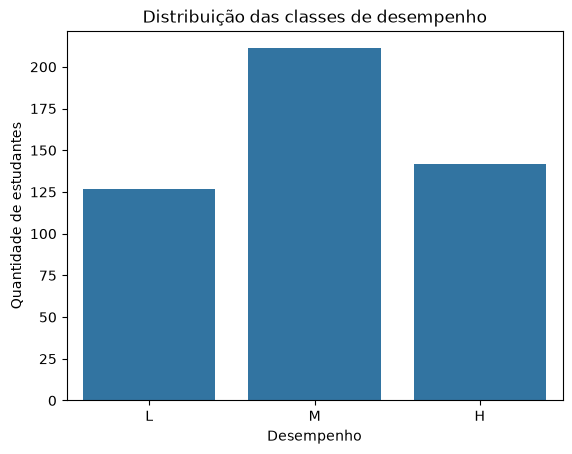

In [17]:

print(df_original["Class"].value_counts())

sns.countplot(
    data=df_original,
    x="Class",
    order=["L", "M", "H"]
)

plt.title("Distribuição das classes de desempenho")
plt.xlabel("Desempenho")
plt.ylabel("Quantidade de estudantes")
plt.show()

Em relação ao desempenho acadêmico, a maior parte dos estudantes está classificada no nível médio (44%), seguida dos níveis alto (29,6%) e baixo (26,5%).

Apesar da predominância do desempenho médio, as três categorias possuem uma quantidade significativa de estudantes. Isso será interessante nas próximas etapas, quando poderemos investigar se determinados padrões de interação estão associados a diferentes níveis de desempenho.

A variável de desempenho não será utilizada para formar os clusters, apenas para ajudar na interpretação dos grupos encontrados.

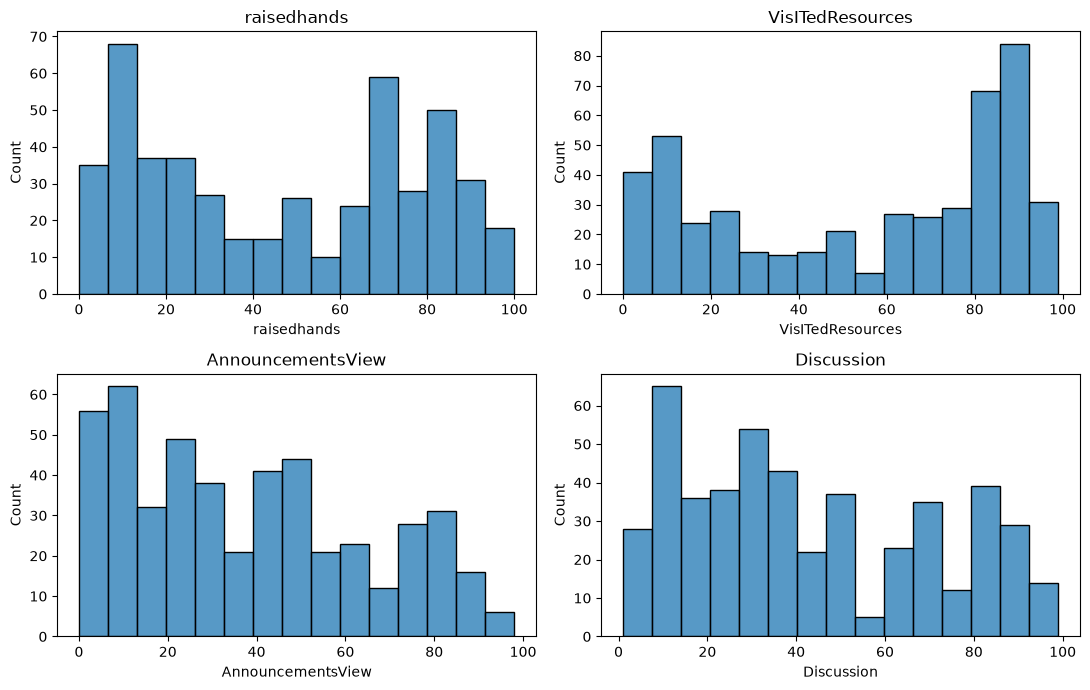

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, coluna in zip(axes.flat, variaveis):
    sns.histplot(
        df_original[coluna],
        bins=15,
        ax=ax
    )
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

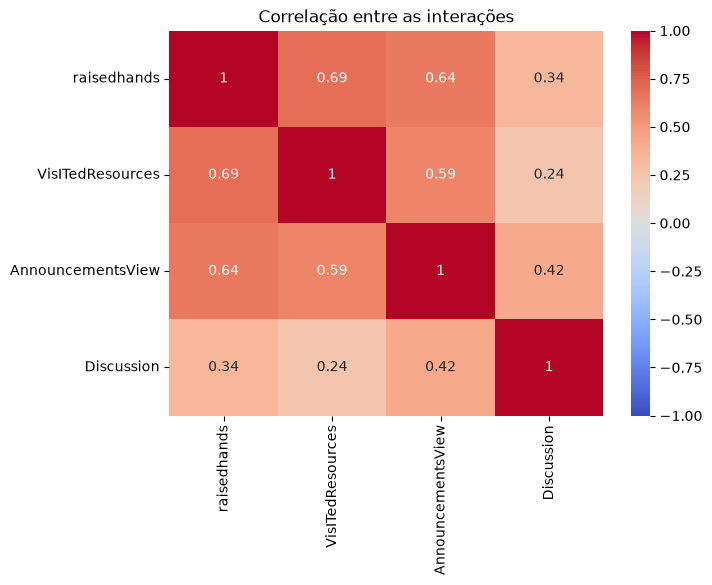

In [19]:
correlacoes = df_original[variaveis].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlacoes,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlação entre as interações")
plt.show()

Nos histogramas, percebemos que os estudantes apresentam diferentes níveis de interação. Em algumas variáveis, como participação em aula e acesso aos recursos educacionais, existem concentrações tanto em valores baixos quanto em valores altos.

A matriz de correlação também revelou algumas relações relevantes. A participação em aula e o acesso aos recursos apresentaram uma correlação positiva de 0,69, o que indica que estudantes que participam mais das aulas também tendem a acessar mais materiais.

Porém, a correlação entre o acesso aos recursos e a participação em discussões foi de apenas 0,24. Isso indica que acessar muitos materiais não significa necessariamente participar mais das discussões.

Essas diferenças reforçam a possibilidade de existirem diferentes padrões de engajamento entre os estudantes.

### Tratamento dos dados

Para preparar os dados, foram selecionadas quatro variáveis relacionadas ao comportamento dos estudantes: participação em aula, acesso aos recursos, visualização de avisos e participação em discussões.

A variável de desempenho acadêmico foi mantida fora dessa etapa, pois será utilizada posteriormente apenas para interpretar os resultados.

Também foi aplicada a padronização das características, para que diferenças de escala e dispersão não influenciem excessivamente os cálculos de distância. Os registros originais foram preservados, permitindo comparar os dados antes e depois da transformação.

(480, 4)


,raisedhands,VisITedResources,AnnouncementsView,Discussion
0,15,16,2,20
1,20,20,3,25
2,10,7,0,30
3,30,25,5,35
4,40,50,12,50


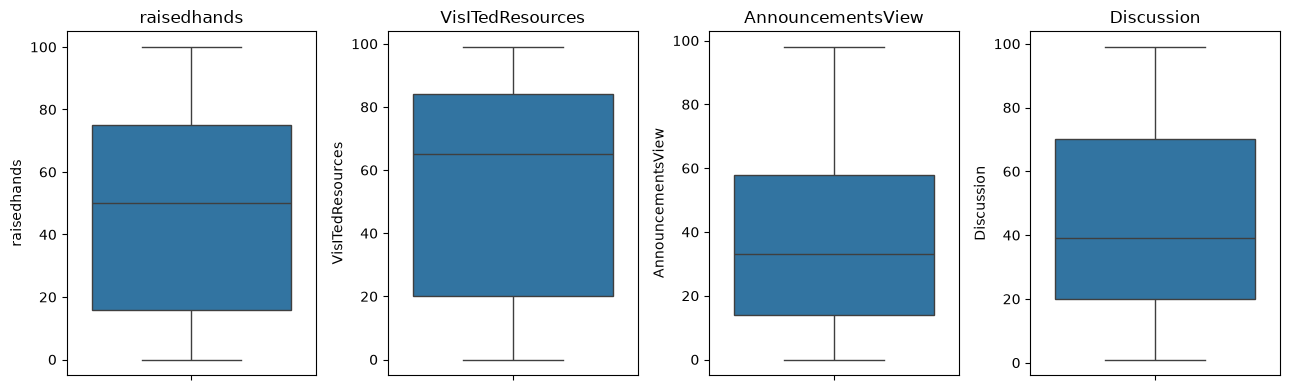

In [20]:
X = df_original[variaveis].copy()

print(X.shape)
display(X.head())

fig, axes = plt.subplots(1, 4, figsize=(13, 4))

for ax, coluna in zip(axes, variaveis):
    sns.boxplot(y=X[coluna], ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

A análise dos boxplots permite identificar possíveis valores extremos nas interações dos estudantes. Entretanto, valores muito altos ou baixos não representam necessariamente erros, pois alguns alunos podem realmente participar mais ou menos das atividades.

Como não foram identificadas evidências suficientes de que esses valores sejam incorretos, optamos por manter os registros, preservando as diferenças de comportamento entre os estudantes.

In [21]:
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=variaveis,
    index=X.index
)

display(X_scaled.describe().round(2))


,raisedhands,VisITedResources,AnnouncementsView,Discussion
count,480.00,480.00,480.00,480.00
mean,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-1.52,-1.66,-1.43,-1.53
25%,-1.01,-1.05,-0.90,-0.84
50%,0.10,0.31,-0.19,-0.16
75%,0.92,0.88,0.76,0.97
max,1.73,1.34,2.26,2.02


In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=X.index
)

print(
    "Variância explicada:",
    pca.explained_variance_ratio_
)

print(
    "Variância acumulada:",
    pca.explained_variance_ratio_.sum()
)

Variância explicada: [0.62714744 0.20387185]
Variância acumulada: 0.8310192894132183


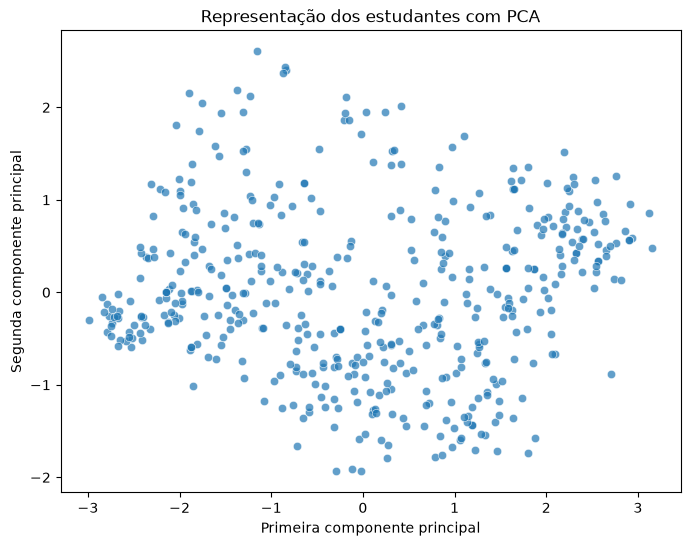

In [23]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    alpha=0.7
)

plt.title("Representação dos estudantes com PCA")
plt.xlabel("Primeira componente principal")
plt.ylabel("Segunda componente principal")
plt.show()

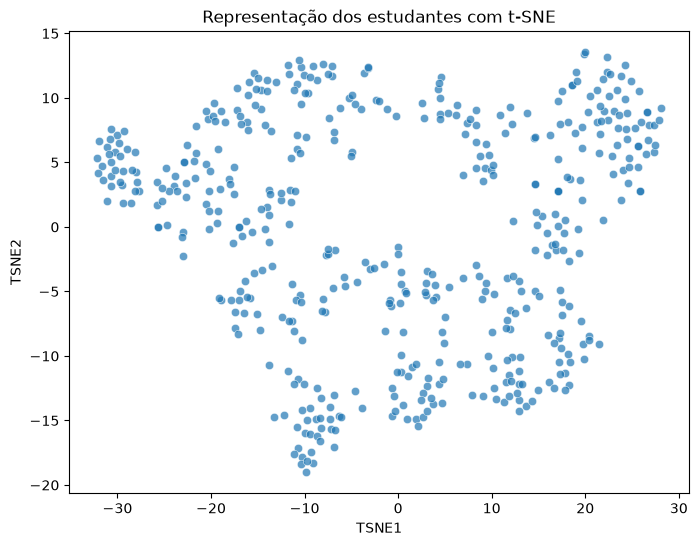

In [24]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

df_tsne = pd.DataFrame(
    X_tsne,
    columns=["TSNE1", "TSNE2"],
    index=X.index
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_tsne,
    x="TSNE1",
    y="TSNE2",
    alpha=0.7
)

plt.title("Representação dos estudantes com t-SNE")
plt.show()

### Representação dos dados

Para facilitar a visualização dos padrões de comportamento dos estudantes, foram utilizadas duas técnicas de redução de dimensionalidade: PCA e t-SNE.

O PCA foi aplicado para representar as quatro variáveis comportamentais em duas componentes principais. A primeira componente explicou aproximadamente 62,71% da variância dos dados e a segunda, 20,39%. Juntas, conseguiram preservar cerca de **83,10% da variância total**, o que indica que a representação em duas dimensões manteve boa parte das informações.

No gráfico do PCA, percebemos que os estudantes estão distribuídos de maneira relativamente contínua, embora existam algumas regiões com maior concentração de pontos. Não aparecem separações completamente definidas entre os possíveis grupos.

Já o t-SNE apresentou uma distribuição visual diferente, destacando algumas regiões de maior concentração e proximidade entre os estudantes.

Essas representações ajudam a compreender melhor a estrutura dos dados e mostram que existem diferenças nos padrões de interação. Entretanto, ainda não podemos afirmar quantos grupos existem ou se eles são bem definidos, pois isso dependerá das próximas etapas da análise.

### Modelagem e escolha do número de clusters

Foi escolhido o algoritmo **K-Means**, que agrupa observações de acordo com a proximidade entre elas. O modelo foi aplicado aos dados padronizados, sem utilizar a variável de desempenho acadêmico (`Class`).

Para selecionar o número de clusters, foram testados valores de 2 a 10. A decisão considera dois critérios: a **inércia**, usada no método do cotovelo, e o **coeficiente de silhouette**, no qual valores maiores indicam grupos mais coesos e mais separados.

,k,Inércia,Silhouette
0,2,1022.803,0.398
1,3,753.895,0.361
2,4,629.297,0.334
3,5,540.586,0.337
4,6,473.353,0.326
5,7,419.446,0.333
6,8,383.718,0.315
7,9,357.063,0.315
8,10,331.963,0.316


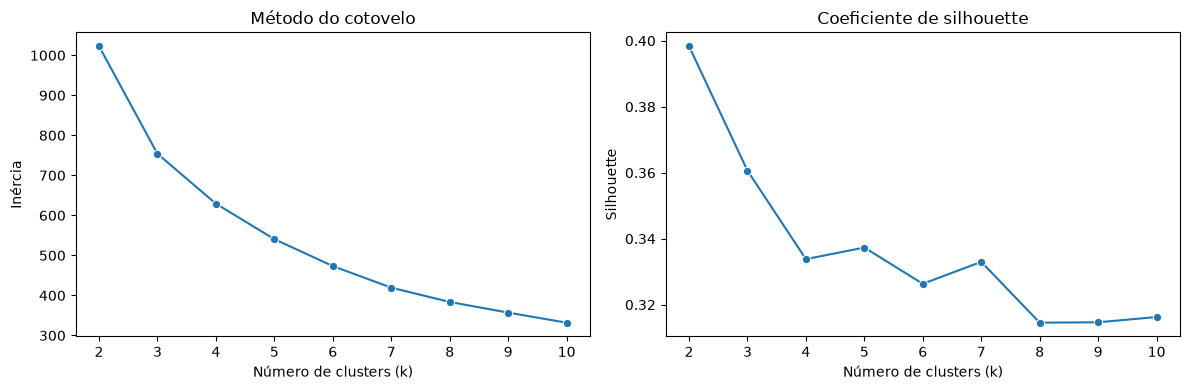

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

resultados_k = []

for k in range(2, 11):
    modelo_teste = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    rotulos_teste = modelo_teste.fit_predict(X_scaled)

    resultados_k.append({
        "k": k,
        "Inércia": modelo_teste.inertia_,
        "Silhouette": silhouette_score(X_scaled, rotulos_teste)
    })

avaliacao_k = pd.DataFrame(resultados_k)
display(avaliacao_k.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(
    data=avaliacao_k,
    x="k",
    y="Inércia",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Método do cotovelo")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inércia")
axes[0].set_xticks(avaliacao_k["k"])

sns.lineplot(
    data=avaliacao_k,
    x="k",
    y="Silhouette",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Coeficiente de silhouette")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette")
axes[1].set_xticks(avaliacao_k["k"])

plt.tight_layout()
plt.show()

O maior coeficiente de silhouette foi obtido com **k = 2**, com valor aproximado de **0,398**. A curva de inércia também apresenta sua maior redução nos primeiros valores de `k`, seguida por ganhos progressivamente menores.

Por isso, foram escolhidos **dois clusters**. Além de apresentar a melhor separação segundo a silhouette, essa solução é mais simples e interpretável para o objetivo do trabalho. O valor da silhouette é moderado, portanto os grupos representam tendências de comportamento, e não divisões completamente isoladas.

In [26]:
k_escolhido = 2

kmeans = KMeans(
    n_clusters=k_escolhido,
    random_state=42,
    n_init=20
)

rotulos_clusters = kmeans.fit_predict(X_scaled)

medias_cluster_padronizadas = (
    X_scaled
    .assign(Cluster=rotulos_clusters)
    .groupby("Cluster")[variaveis]
    .mean()
)

ordem_clusters = (
    medias_cluster_padronizadas
    .mean(axis=1)
    .sort_values()
    .index
    .tolist()
)

mapa_perfis = {
    ordem_clusters[0]: "Baixo engajamento",
    ordem_clusters[1]: "Alto engajamento"
}

df_resultados = df_original.copy()
df_resultados["Cluster"] = rotulos_clusters
df_resultados["Perfil"] = df_resultados["Cluster"].map(mapa_perfis)

resumo_tamanho = (
    df_resultados
    .groupby(["Cluster", "Perfil"])
    .size()
    .rename("Quantidade")
    .reset_index()
)

display(resumo_tamanho)

,Cluster,Perfil,Quantidade
0,0,Baixo engajamento,231
1,1,Alto engajamento,249


### Interpretação dos clusters

Os nomes dos perfis foram definidos depois da clusterização, comparando as médias das quatro variáveis. Assim, o nome ajuda a comunicar o comportamento predominante de cada grupo, mas não foi usado pelo algoritmo para formá-lo.

,Quantidade,raisedhands,VisITedResources,AnnouncementsView,Discussion
Perfil,,,,,
Baixo engajamento,231,20.5,28.4,19.2,32.6
Alto engajamento,249,71.2,79.3,55.3,53.2


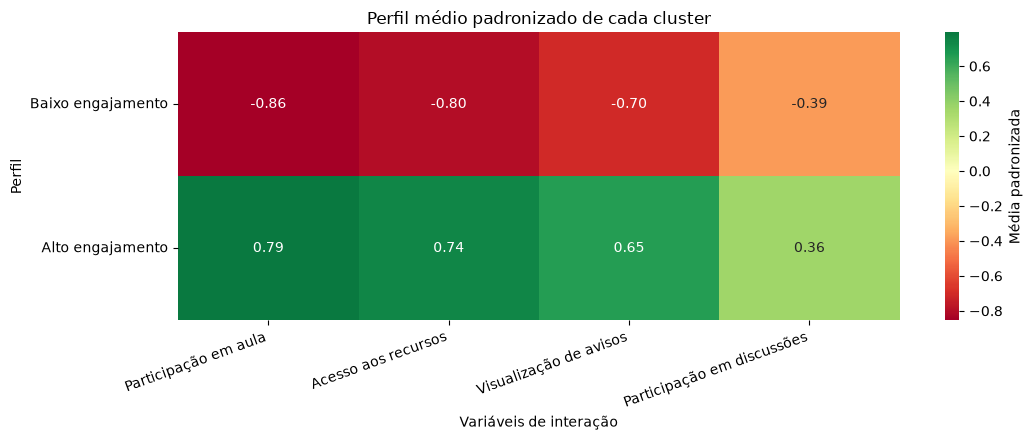

In [27]:
ordem_perfis = ["Baixo engajamento", "Alto engajamento"]

medias_originais = (
    df_resultados
    .groupby("Perfil")[variaveis]
    .mean()
    .reindex(ordem_perfis)
)

quantidades = (
    df_resultados["Perfil"]
    .value_counts()
    .reindex(ordem_perfis)
)

resumo_perfis = medias_originais.copy()
resumo_perfis.insert(0, "Quantidade", quantidades)
display(resumo_perfis.round(1))

perfil_padronizado = (
    X_scaled
    .assign(Perfil=df_resultados["Perfil"])
    .groupby("Perfil")[variaveis]
    .mean()
    .reindex(ordem_perfis)
)

nomes_variaveis = {
    "raisedhands": "Participação em aula",
    "VisITedResources": "Acesso aos recursos",
    "AnnouncementsView": "Visualização de avisos",
    "Discussion": "Participação em discussões"
}

plt.figure(figsize=(11, 4.5))
sns.heatmap(
    perfil_padronizado.rename(columns=nomes_variaveis),
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    cbar_kws={"label": "Média padronizada"}
)
plt.title("Perfil médio padronizado de cada cluster")
plt.xlabel("Variáveis de interação")
plt.ylabel("Perfil")
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

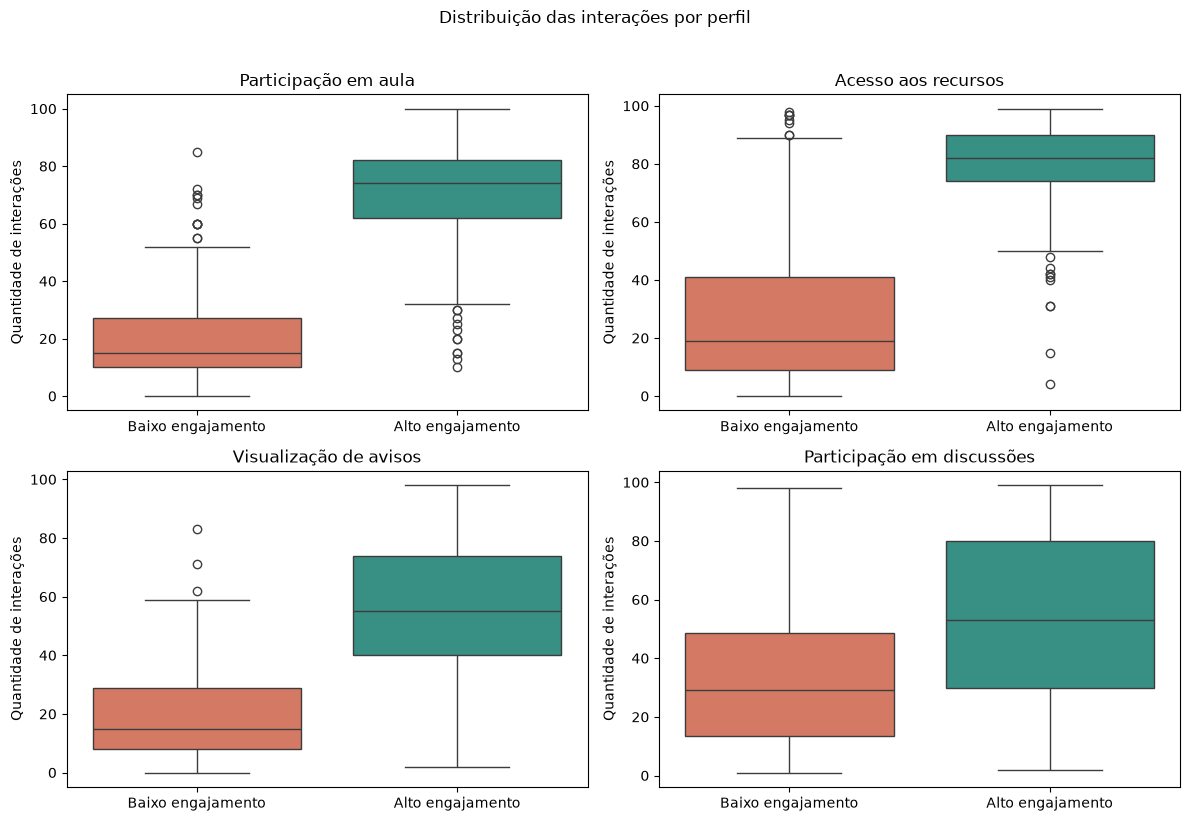

In [28]:
cores_perfis = {
    "Baixo engajamento": "#E76F51",
    "Alto engajamento": "#2A9D8F"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, coluna in zip(axes.flat, variaveis):
    sns.boxplot(
        data=df_resultados,
        x="Perfil",
        y=coluna,
        order=ordem_perfis,
        hue="Perfil",
        palette=cores_perfis,
        legend=False,
        ax=ax
    )
    ax.set_title(nomes_variaveis[coluna])
    ax.set_xlabel("")
    ax.set_ylabel("Quantidade de interações")

plt.suptitle("Distribuição das interações por perfil", y=1.02)
plt.tight_layout()
plt.show()

### Relação entre os clusters e o desempenho acadêmico

A variável `Class` não participou da criação dos clusters. Ela é usada somente nesta etapa, como uma variável externa para ajudar a interpretar se os padrões de interação encontrados estão associados ao desempenho acadêmico.

,Baixo (L),Médio (M),Alto (H)
Perfil,,,
Baixo engajamento,53.2,39.8,6.9
Alto engajamento,1.6,47.8,50.6


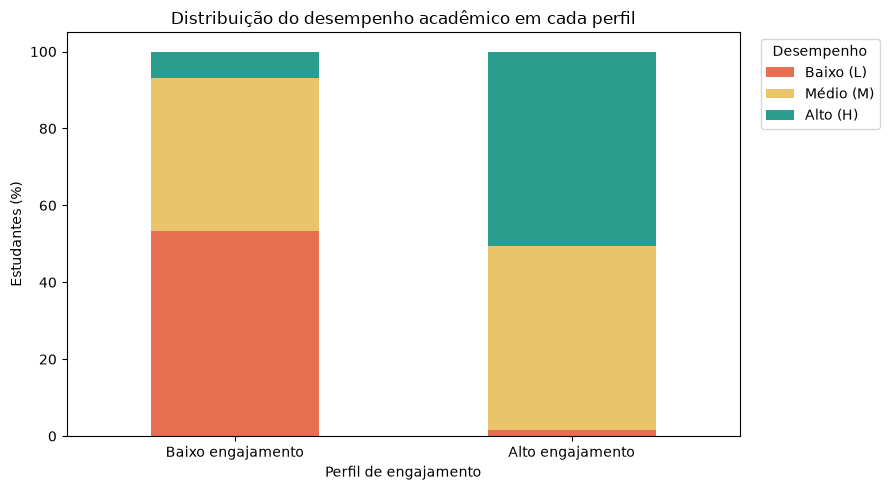

In [29]:
desempenho_percentual = (
    pd.crosstab(
        df_resultados["Perfil"],
        df_resultados["Class"],
        normalize="index"
    )
    .mul(100)
    .reindex(index=ordem_perfis, columns=["L", "M", "H"], fill_value=0)
)

desempenho_percentual.columns = [
    "Baixo (L)",
    "Médio (M)",
    "Alto (H)"
]

display(desempenho_percentual.round(1))

ax = desempenho_percentual.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#E76F51", "#E9C46A", "#2A9D8F"]
)

ax.set_title("Distribuição do desempenho acadêmico em cada perfil")
ax.set_xlabel("Perfil de engajamento")
ax.set_ylabel("Estudantes (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Desempenho", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

O perfil de **baixo engajamento** reúne 231 estudantes. Ele apresenta médias de 20,5 em participação em aula, 28,4 em acesso aos recursos, 19,2 em visualização de avisos e 32,6 em discussões. Nesse grupo, **53,2%** dos estudantes têm desempenho baixo, 39,8% médio e apenas 6,9% alto.

O perfil de **alto engajamento** reúne 249 estudantes. Suas médias são maiores nas quatro variáveis: 71,2 em participação em aula, 79,3 em acesso aos recursos, 55,3 em visualização de avisos e 53,2 em discussões. Nesse grupo, **50,6%** dos estudantes têm desempenho alto, 47,8% médio e apenas 1,6% baixo.

Os resultados mostram uma associação clara entre maior interação e melhor desempenho. Porém, essa associação não demonstra causalidade: com estes dados, não é possível concluir que o engajamento, sozinho, tenha causado o desempenho observado.

### Visualização dos clusters

As projeções PCA e t-SNE calculadas anteriormente são apresentadas novamente, agora coloridas de acordo com o perfil atribuído pelo K-Means. O PCA ajuda a observar a separação global dos grupos, enquanto o t-SNE destaca relações locais de proximidade.

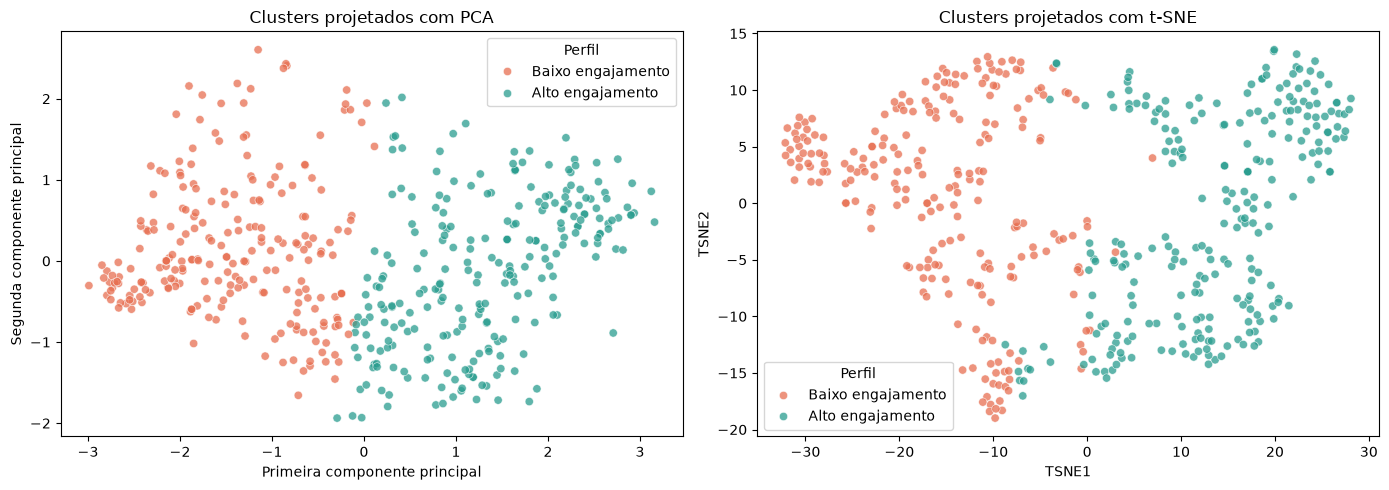

In [30]:
df_pca_clusters = df_pca.assign(Perfil=df_resultados["Perfil"])
df_tsne_clusters = df_tsne.assign(Perfil=df_resultados["Perfil"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df_pca_clusters,
    x="PC1",
    y="PC2",
    hue="Perfil",
    hue_order=ordem_perfis,
    palette=cores_perfis,
    alpha=0.75,
    ax=axes[0]
)
axes[0].set_title("Clusters projetados com PCA")
axes[0].set_xlabel("Primeira componente principal")
axes[0].set_ylabel("Segunda componente principal")

sns.scatterplot(
    data=df_tsne_clusters,
    x="TSNE1",
    y="TSNE2",
    hue="Perfil",
    hue_order=ordem_perfis,
    palette=cores_perfis,
    alpha=0.75,
    ax=axes[1]
)
axes[1].set_title("Clusters projetados com t-SNE")

for ax in axes:
    ax.legend(title="Perfil")

plt.tight_layout()
plt.show()

### Exemplos representativos

Para tornar os perfis mais concretos, foi selecionado o registro mais próximo do centroide de cada cluster. Esses registros funcionam como exemplos típicos do comportamento médio de cada grupo, mas não representam todos os estudantes daquele perfil.

In [31]:
distancias_centroides = kmeans.transform(X_scaled)
df_resultados["Distancia_ao_centroide"] = distancias_centroides[
    np.arange(len(X_scaled)),
    rotulos_clusters
]

indices_prototipos = (
    df_resultados
    .groupby("Perfil")["Distancia_ao_centroide"]
    .idxmin()
)

colunas_prototipos = [
    "Perfil",
    *variaveis,
    "Class",
    "Distancia_ao_centroide"
]

prototipos = df_resultados.loc[indices_prototipos, colunas_prototipos].copy()
prototipos.insert(0, "Registro", prototipos.index)
prototipos["Perfil"] = pd.Categorical(
    prototipos["Perfil"],
    categories=ordem_perfis,
    ordered=True
)

display(prototipos.sort_values("Perfil").round(3))

,Registro,Perfil,raisedhands,VisITedResources,AnnouncementsView,Discussion,Class,Distancia_ao_centroide
324,324,Baixo engajamento,24,35,18,31,M,0.241
150,150,Alto engajamento,80,80,51,59,H,0.391


### Conclusões

A análise identificou dois perfis principais de estudantes: um grupo com níveis mais baixos de interação nas quatro atividades observadas e outro com níveis mais altos. O perfil de alto engajamento concentra principalmente estudantes com desempenho médio ou alto, enquanto o perfil de baixo engajamento apresenta maior concentração de desempenho baixo.

Portanto, os dados sugerem que participação em aula, acesso aos recursos, visualização de avisos e participação em discussões formam padrões conjuntos de engajamento relacionados ao desempenho acadêmico. Na prática, esses perfis podem ajudar a identificar grupos que merecem acompanhamento e ações de apoio, desde que não sejam usados para rotular ou punir estudantes.

### Limitações

- A base possui apenas 480 registros e quatro variáveis foram utilizadas na clusterização.
- Os dois registros repetidos foram mantidos porque não existe um identificador único que permita confirmar se são duplicatas reais.
- O K-Means é sensível à escala, à inicialização e ao formato dos grupos; a padronização e as múltiplas inicializações reduzem, mas não eliminam essas limitações.
- O coeficiente de silhouette foi moderado, mostrando que existe alguma sobreposição entre os perfis.
- A associação entre engajamento e desempenho não permite estabelecer uma relação de causa e efeito.
- O t-SNE é uma ferramenta de visualização e pode mudar conforme seus parâmetros; ele não foi utilizado para formar os clusters.

### Próximos passos

- Avaliar a estabilidade dos clusters em diferentes amostras e períodos.
- Comparar o K-Means com métodos hierárquicos, DBSCAN ou Gaussian Mixture.
- Incorporar outras informações relevantes, como frequência, características das disciplinas e evolução temporal das interações.
- Validar os perfis com especialistas da área educacional e acompanhar se intervenções de apoio produzem resultados positivos.
- Investigar possíveis vieses antes de qualquer uso prático, preservando a privacidade e evitando decisões automatizadas sobre estudantes.